In [1]:
import pandas as pd
import numpy as np
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

RAW_DIR = Path("../data/raw/UAlpha40 A Comprehensive Dataset of Urdu alphabets for Pakistan Sign Language")

test_df = pd.read_csv("../data/processed/test.csv")
feature_cols = [f"f{i}" for i in range(63)]

print("Test set:", test_df.shape)
test_df.head(2)

Test set: (562, 66)


,label,signer_id,filename,f0,f1,f2,f3,f4,f5,f6,...,f53,f54,f55,f56,f57,f58,f59,f60,f61,f62
0,1-Hay,s0251,s0251-10hay.jpg,0.0,0.0,0.0,0.144057,-0.696173,-0.046720,0.478123,...,-0.447511,1.054861,0.101863,-0.502622,0.969267,-0.009833,-0.403517,0.802021,-0.035178,-0.308149
1,1-Hay,s0255,s0255-10hay.jpg,0.0,0.0,0.0,0.158055,-0.737145,-0.027868,0.540961,...,-0.428798,0.964727,0.187479,-0.415738,0.902752,0.045193,-0.299164,0.784328,-0.024990,-0.207970


In [2]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

RANDOM_SEED = 42

train_df = pd.read_csv("../data/processed/train.csv")
X_train = train_df[feature_cols].to_numpy(dtype=np.float64)
y_train = train_df["label"].astype(str).to_numpy()

X_test = test_df[feature_cols].to_numpy(dtype=np.float64)
y_test = test_df["label"].astype(str).to_numpy()

best_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", SVC(kernel="rbf", C=100, gamma=0.01, probability=True))
])
best_model.fit(X_train, y_train)

test_preds = best_model.predict(X_test)
print("Model trained again. Test accuracy:", round((test_preds == y_test).mean(), 4))

D:\CS 5 Course\ML(Lab)\Project\psl-translator\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Model trained again. Test accuracy: 0.9502


In [3]:
wrong_mask = test_preds != y_test
wrong_df = test_df[wrong_mask].copy()
wrong_df["predicted"] = test_preds[wrong_mask]

print("Total wrong predictions:", len(wrong_df))

Total wrong predictions: 28


In [4]:
# Take only one example from each different "true letter", for variety
diverse_errors = wrong_df.drop_duplicates(subset="label").head(8)

print("Chosen mistakes:")
diverse_errors[["filename", "label", "predicted"]]

Chosen mistakes:


,filename,label,predicted
18,s0264-25ain.jpg,Ain,Ghain
31,s0255-02alif.jpg,Alif,Ain
114,s0276-13daal.jpg,Daal,Tuey
187,s0251-26ghain.JPG,Ghain,Ain
306,s0301-33nuun.JPG,Nuun,Alif
311,s0251-34nuungh.JPG,Nuungh,Kiaf
351,s0287-15ray.jpg,Ray,Zaal
435,s0305-06taay.JPG,Taay,Seen


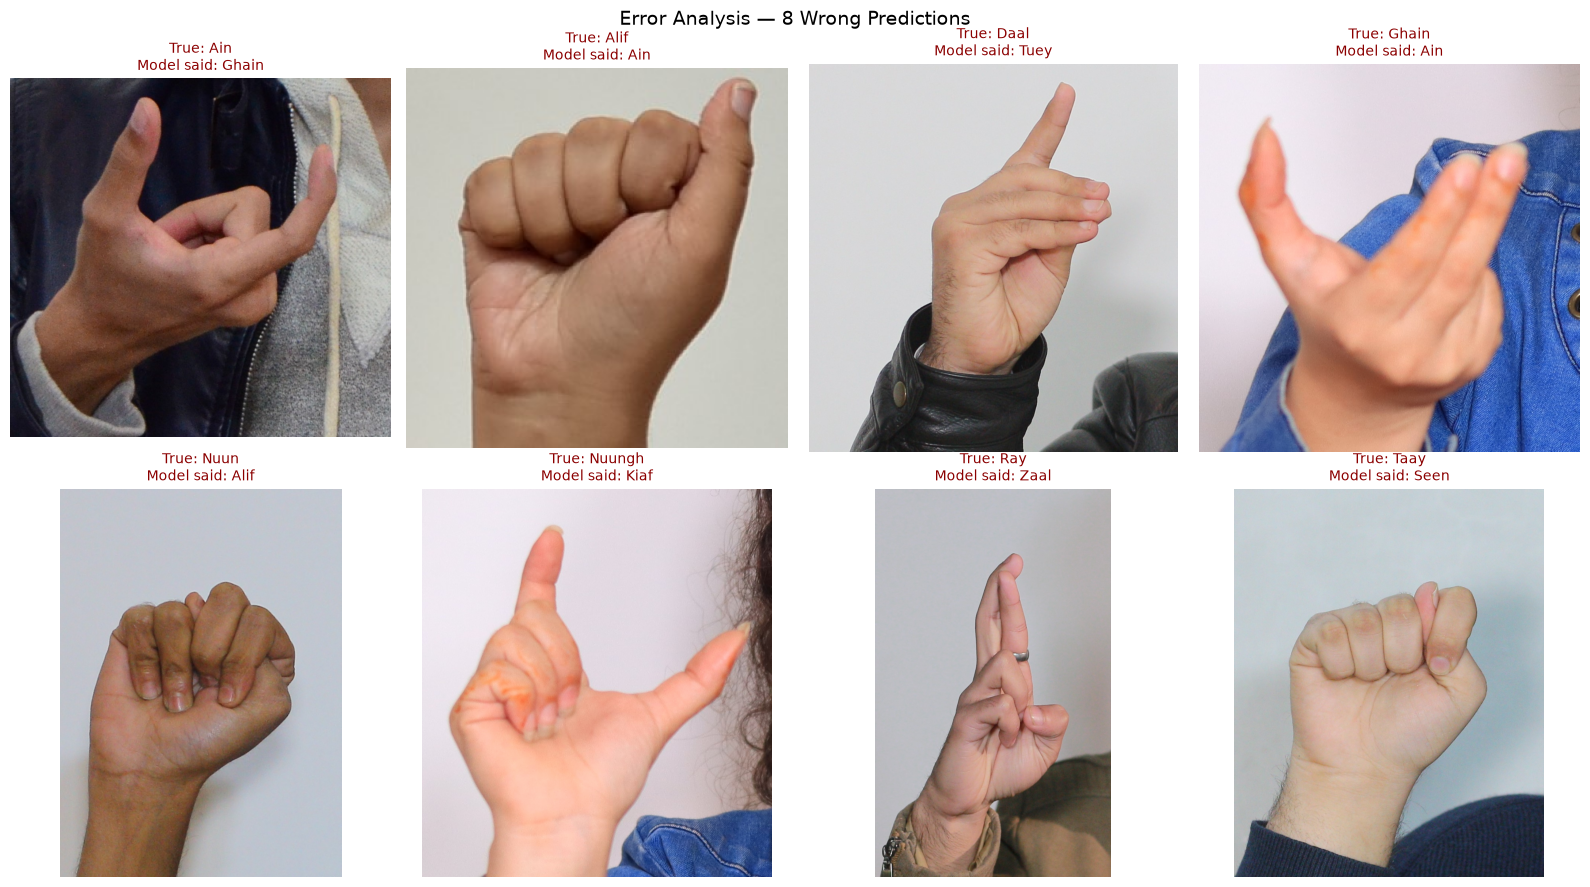

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(16, 9))
axes = axes.flatten()

for ax, (_, row) in zip(axes, diverse_errors.iterrows()):
    img_path = RAW_DIR / f"{row['label']}-Original" / row["filename"]
    img = cv2.imread(str(img_path))
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    ax.imshow(img_rgb)
    ax.set_title(f"True: {row['label']}\nModel said: {row['predicted']}", fontsize=10, color="darkred")
    ax.axis("off")

plt.suptitle("Error Analysis — 8 Wrong Predictions", fontsize=14)
plt.tight_layout()
plt.savefig("../reports/figures/06_error_examples.png", dpi=150)
plt.show()